# Wo hört Whisper hin? – Zeitliche und spektrale Lokalisierung der Evidenz für einzelne Wörter

**Forschungsfrage:** Welche Zeitabschnitte und akustischen Merkmale des Eingangssignals sind für die Transkription einzelner Wörter durch Whisper entscheidend – und wie gut lokalisieren Input-Attribution und Attention-Mechanismen diese Evidenz im Vergleich zu den tatsächlichen Wortgrenzen?

| Teilfrage | Methode | Abschnitt |
|---|---|---|
| TF1 Zeitliche Lokalisierung | Integrated Gradients, Gradient×Δ, Zeit-Occlusion vs. MFA-Wortgrenzen | 8 |
| TF2 Spektrale Merkmale | IG-Profil über Mel-Bänder, Frequenzband-Occlusion; Funktions- vs. Inhaltswörter | 9 |
| TF3 Cross-Attention | Pointing Game / Masse-im-Wort je Decoder-Kopf, Vergleich mit OpenAIs *alignment heads* | 10 |
| TF4 Encoder-Self-Attention | Kopf-Statistiken (Lokalität, Distanz, Padding-Sink, Wortbindung) je Schicht | 11 |
| TF5 Faithfulness | Deletion-Test je Methode, Ablation einzelner Köpfe (Δ log p, WER) | 12 |
| Skalierung | whisper-tiny vs. whisper-base | 13 |

Dokumentation, Hypothesen und Quellen: siehe `README.md`. Laufzeitumgebung: GPU empfohlen (z. B. Colab T4).

In [1]:
%pip -q install "transformers>=4.40" "datasets>=2.18" soundfile librosa tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import io, os, re, math, json, random, difflib, warnings
from collections import defaultdict
from contextlib import contextmanager

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, soundfile as sf, librosa, transformers, datasets
from scipy import stats
from tqdm.auto import tqdm
from datasets import load_dataset, Audio
from transformers import WhisperForConditionalGeneration, WhisperProcessor

warnings.filterwarnings("ignore")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("torch", torch.__version__, "| transformers", transformers.__version__, "| datasets", datasets.__version__, "|", DEVICE)

QUICK = False   # True: Mini-Lauf zum Testen der Pipeline
CFG = dict(
    models      = ["openai/whisper-tiny", "openai/whisper-base"],
    n_utt       = 10 if QUICK else 100,  # Äußerungen für TF1–TF4
    n_faith     = 3  if QUICK else 25,   # Teilmenge für Deletion + Ablation (teuer)
    max_dur     = 15.0,                  # s
    ig_steps    = 32, ig_batch = 8,      # Integrated Gradients
    occ_win     = 0.10, occ_stride = 0.05,  # s, Zeit-Occlusion
    n_bands     = 8,                     # Frequenzband-Occlusion
    tol         = 0.02,                  # s, Toleranz Pointing Game
    ctx         = 0.30,                  # s, Kontextfenster vor/nach dem Wort
    del_fracs   = [0.25, 0.5, 1, 2, 4],  # entfernte Frames als Vielfaches der Wortlänge
    batch       = 16,                    # Batchgröße für Forward-only-Perturbationen
    ablation_wer= True,                  # WER unter Kopf-Ablation (Generierung, langsamer)
)
SR, HOP, ENC_HOP, N_MEL, N_FRAMES = 16000, 0.01, 0.02, 80, 3000   # Mel-Frame 10 ms, Encoder-Frame 20 ms
BINS = np.round(np.arange(-2.0, 3.01, 0.1), 2)   # relative Zeit (0 = Wortanfang, 1 = Wortende)
os.makedirs("results", exist_ok=True)

torch 2.15.0+cpu | transformers 5.23.0 | datasets 5.2.0 | cpu


## 1 Daten: LibriSpeech `test-clean` mit Wortgrenzen

Wir nutzen `gilkeyio/librispeech-alignments` (Hugging Face): LibriSpeech-Audio (16 kHz) plus Wort- und Phonem-Alignments des **Montreal Forced Aligner** (McAuliffe et al., 2017; Alignments von Lugosch et al., 2019). Die MFA-Grenzen dienen als **Referenz („Ground Truth“)** für die Lokalisierung. Sie sind selbst modellbasiert und haben eine Unsicherheit von etwa einem Phonem; deshalb gibt es eine Toleranz `tol`.

Es wird nur der Split `test_clean` gestreamt, nicht der ganze Datensatz. Audio wird selbst mit `soundfile` dekodiert, damit das unabhängig von der `datasets`-Version funktioniert.

In [3]:
FUNCTION_WORDS = set("""a an the and or but if of to in on at by for with from as into onto upon
about than then so that this these those there here is are was were be been being am do does did
have has had i you he she it we they me him her us them my your his its our their mine not no nor
will would shall should can could may might must what which who whom whose when where why how
all any some such very just also too up out off over own same both each few more most other""".split())

def norm(w: str) -> str:
    """Normalisierung für den Wortvergleich: klein, nur a-z, 0-9 und Apostroph."""
    return re.sub(r"[^a-z0-9']", "", w.lower())

def parse_words(w):
    """MFA-Wortliste -> [{word,start,end}] (verträgt list-of-dict und dict-of-lists)."""
    if isinstance(w, dict):
        w = [dict(zip(w.keys(), v)) for v in zip(*w.values())]
    out = [dict(word=norm(x["word"]), start=float(x["start"]), end=float(x["end"])) for x in w]
    return [x for x in out if x["word"] and x["end"] > x["start"]]

def load_utterances(n, max_dur, split="test_clean", seed=SEED):
    ds = load_dataset("gilkeyio/librispeech-alignments", split=split, streaming=True)
    ds = ds.cast_column("audio", Audio(decode=False)).shuffle(seed=seed, buffer_size=500)
    out = []
    for ex in ds:
        a = ex["audio"]
        wav, sr = sf.read(io.BytesIO(a["bytes"])) if a.get("bytes") else sf.read(a["path"])
        wav = wav.mean(1) if wav.ndim > 1 else wav
        if sr != SR:
            wav = librosa.resample(wav, orig_sr=sr, target_sr=SR)
        dur = len(wav) / SR
        words = parse_words(ex["words"])
        if dur > max_dur or len(words) < 3:
            continue
        out.append(dict(id=ex["id"], wav=wav.astype(np.float32), dur=dur, words=words))
        if len(out) >= n:
            break
    return out

def wer(ref, hyp):
    """Word Error Rate über Levenshtein-Distanz auf Wortebene."""
    d = np.arange(len(hyp) + 1)
    for i, r in enumerate(ref, 1):
        prev, d = d, d.copy(); d[0] = i
        for j, h in enumerate(hyp, 1):
            d[j] = min(prev[j] + 1, d[j - 1] + 1, prev[j - 1] + (r != h))
    return d[-1] / max(len(ref), 1)

def match_words(hyp, ref):
    """Index-Paare (hyp_i, ref_j) identischer Wörter in optimaler Ausrichtung (difflib)."""
    sm = difflib.SequenceMatcher(a=hyp, b=ref, autojunk=False)
    return [(b.a + k, b.b + k) for b in sm.get_matching_blocks() for k in range(b.size)]

In [4]:
utts = load_utterances(CFG["n_utt"], CFG["max_dur"])
durs = np.array([u["dur"] for u in utts]); wd = np.array([w["end"] - w["start"] for u in utts for w in u["words"]])
print(f"{len(utts)} Äußerungen | Dauer {durs.mean():.1f}±{durs.std():.1f}s | {len(wd)} Wörter | Wortdauer Median {1000*np.median(wd):.0f} ms")

Resolving data files:   0%|          | 0/49 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/66 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/49 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/66 [00:00<?, ?it/s]

100 Äußerungen | Dauer 6.8±3.2s | 1868 Wörter | Wortdauer Median 260 ms


## 2 Modell-Wrapper

**Architektur (Radford et al., 2023):** Audio → 80-Kanal-Log-Mel-Spektrogramm (25 ms Fenster, 10 ms Hop), **immer auf 30 s aufgefüllt** (3000 Frames) → 2 Conv-Schichten (die zweite mit Stride 2) → Transformer-Encoder mit 1500 Frames à 20 ms → autoregressiver Decoder mit Cross-Attention auf den Encoder.

**Vorgehen pro Äußerung**
1. Whisper transkribiert greedy (Prompt `<|startoftranscript|><|en|><|transcribe|><|notimestamps|>`).
2. BPE-Tokens werden zu Wörtern gruppiert: Ein Token mit führendem Leerzeichen beginnt ein neues Wort, reine Satzzeichen-Tokens werden ignoriert.
3. Die erkannten Wörter werden per `difflib` mit den Referenzwörtern ausgerichtet. Analysiert werden **nur korrekt erkannte Wörter**, denn nur für sie ist die MFA-Grenze die richtige Referenz.
4. Ein Forward-Pass mit **Teacher Forcing** auf die eigene Hypothese liefert $\log p(\text{Wort}) = \sum_{t\in\text{Wort}} \log p(y_t \mid y_{<t}, X)$. Diese Größe ist das Erklärungsziel $f(X)$ für alle Attributionsmethoden.

**Baseline $X_0$ („Stille“):** Das Padding-Spektrum der jeweiligen Äußerung. Der Feature-Extractor begrenzt Log-Mel-Werte nach unten auf (Maximum − 8). Aufgefüllte Nullen landen genau auf diesem Wert. Für das Modell ist $X_0$ also exakt das, was es als Stille kennt, und erzeugt keine Out-of-Distribution-Eingabe wie etwa ein Null-Tensor.

Es werden zwei Kopien des Modells geladen: `eager` für Attention-Gewichte und Hooks, `sdpa` für schnellere Gradienten und Perturbationen.

In [5]:
class WhisperXAI:
    def __init__(self, name):
        self.name = name
        self.proc = WhisperProcessor.from_pretrained(name)
        self.tok = self.proc.tokenizer
        load = lambda impl: WhisperForConditionalGeneration.from_pretrained(name, attn_implementation=impl).to(DEVICE).eval()
        self.model = load("eager")                       # Attention-Gewichte, Ablation-Hooks
        try:    self.model_g = load("sdpa")              # Gradienten / Perturbationen
        except Exception: self.model_g = self.model
        for m in {self.model, self.model_g}:
            for p in m.parameters(): p.requires_grad_(False)
        c = self.model.config
        self.L_enc, self.L_dec = c.encoder_layers, c.decoder_layers
        self.H_enc, self.H_dec = c.encoder_attention_heads, c.decoder_attention_heads
        self.prefix = self.tok.convert_tokens_to_ids(["<|startoftranscript|>", "<|en|>", "<|transcribe|>", "<|notimestamps|>"])
        self.eos = self.tok.eos_token_id                 # alle Spezialtokens haben IDs >= eos
        ah = getattr(self.model.generation_config, "alignment_heads", None)
        self.align = [tuple(x) for x in ah] if ah else None
        print(f"{name}: Encoder {self.L_enc}x{self.H_enc}, Decoder {self.L_dec}x{self.H_dec}, alignment heads = {self.align}")

    def features(self, wav):
        return self.proc.feature_extractor(wav, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)

    @torch.no_grad()
    def transcribe(self, feats, model=None):
        gen = (model or self.model_g).generate(feats, language="en", task="transcribe", max_new_tokens=200)
        return [t for t in gen[0].tolist() if t < self.eos]   # nur Text-Tokens

    def token_words(self, text_ids):
        """[(norm_wort, [Indizes in text_ids])] – Satzzeichen-Tokens werden nicht als Wort-Tokens gezählt."""
        words = []
        for i, t in enumerate(text_ids):
            s = self.tok.decode([t])
            if s.startswith(" ") or not words:
                words.append(["", []])
            words[-1][0] += s
            if norm(s):
                words[-1][1].append(i)
        return [(norm(w), idx) for w, idx in words if norm(w) and idx]

    def prepare(self, utt):
        feats = self.features(utt["wav"])
        text_ids = self.transcribe(feats)
        hyp = self.token_words(text_ids)
        ref = utt["words"]
        P = len(self.prefix)
        words = []
        for hi, ri in match_words([h[0] for h in hyp], [r["word"] for r in ref]):
            r = ref[ri]
            words.append(dict(word=r["word"], start=r["start"], end=r["end"], ref_idx=ri,
                              tok_pos=[P + i for i in hyp[hi][1]],   # Positionen in seq
                              func=r["word"] in FUNCTION_WORDS))
        return dict(id=utt["id"], dur=utt["dur"], ref_words=ref, feats=feats,
                    baseline=feats[..., -1:].expand_as(feats).clone(),   # Padding-Spektrum = Stille
                    seq=self.prefix + text_ids + [self.eos], words=words,
                    hyp_words=[h[0] for h in hyp], text=self.tok.decode(text_ids),
                    T=min(int(np.ceil(utt["dur"] / HOP)), N_FRAMES),
                    n_a=min(int(np.ceil(utt["dur"] / ENC_HOP)), N_FRAMES // 2))

    def token_logprobs(self, model, feats, seq):
        """(B, len(seq)-1): log p(seq[j+1] | seq[:j+1], X) mit Teacher Forcing."""
        B = feats.shape[0]
        dec = torch.tensor(seq[:-1], device=DEVICE).unsqueeze(0).expand(B, -1)
        logits = model(input_features=feats, decoder_input_ids=dec).logits.float()
        tgt = torch.tensor(seq[1:], device=DEVICE).view(1, -1, 1).expand(B, -1, 1)
        return logits.gather(-1, tgt).squeeze(-1) - logits.logsumexp(-1)

    def word_logprobs(self, model, feats, seq, words):
        """(B, n_words): Summe der Token-Logprobs je Wort."""
        lp = self.token_logprobs(model, feats, seq)
        return torch.stack([lp[:, [p - 1 for p in w["tok_pos"]]].sum(-1) for w in words], -1)

## 3 Input-Attribution

Alle Methoden erklären $f(X)=\log p(\text{Wort}\mid X)$ bezüglich des Log-Mel-Spektrogramms $X\in\mathbb{R}^{80\times3000}$.

* **Integrated Gradients** (Sundararajan et al., 2017): $\mathrm{IG}_i = (x_i - x_{0,i}) \int_0^1 \frac{\partial f(x_0+\alpha(x-x_0))}{\partial x_i}\,d\alpha$. Das Integral wird mit der Mittelpunktsregel über `ig_steps` Stützstellen angenähert. Nach dem Axiom der *Completeness* gilt $\sum_i \mathrm{IG}_i = f(x)-f(x_0)$. Daran prüfen wir, ob die Näherung konvergiert ist.
* **Gradient × Δ** (Shrikumar et al., 2016, mit Baseline): $\nabla f(x)\odot(x-x_0)$. Entspricht IG mit einer einzigen Stützstelle bei $\alpha=1$, ist also lokal und billig, verletzt aber bei Sättigung die Completeness.
* **Zeit-Occlusion** (Zeiler & Fergus, 2014): Ein 100-ms-Fenster wird auf $x_0$ gesetzt und der Abfall von $\log p$ gemessen. Modellagnostisch und kausal. Ein Forward-Pass liefert alle Wörter gleichzeitig. Überlappende Fenster werden pro Frame gemittelt.
* **Frequenzband-Occlusion:** 8 Mel-Bandgruppen werden *nur innerhalb des Wortsegments* (±50 ms) auf $x_0$ gesetzt.

Für die Zeitlokalisierung wird $|{\rm Attribution}|$ über die Mel-Achse summiert. Bei Occlusion wird nur der positive Teil verwendet, also Fenster, deren Entfernen das Wort unwahrscheinlicher macht.

In [6]:
def integrated_gradients(xai, prep, steps, batch):
    x, x0, seq, words = prep["feats"], prep["baseline"], prep["seq"], prep["words"]
    W = len(words)
    total = torch.zeros(W, *x.shape[1:], device=DEVICE)
    alphas = (torch.arange(steps, device=DEVICE) + 0.5) / steps
    for a in alphas.split(batch):
        xi = (x0 + a.view(-1, 1, 1) * (x - x0)).requires_grad_(True)
        lp = xai.word_logprobs(xai.model_g, xi, seq, words)                 # (b, W)
        for w in range(W):
            g, = torch.autograd.grad(lp[:, w].sum(), xi, retain_graph=w < W - 1)
            total[w] += g.sum(0)
    ig = (x - x0)[0] * total / steps                                       # (W, 80, 3000)
    with torch.no_grad():                                                  # Completeness-Check
        lp_end = xai.word_logprobs(xai.model_g, torch.cat([x, x0]), seq, words)
    delta = (lp_end[0] - lp_end[1])
    rel_err = ((ig.sum((1, 2)) - delta).abs() / delta.abs().clamp_min(1e-6)).cpu().numpy()
    return ig, rel_err

def grad_times_delta(xai, prep):
    x = prep["feats"].clone().requires_grad_(True)
    lp = xai.word_logprobs(xai.model_g, x, prep["seq"], prep["words"])[0]
    out = []
    for w in range(len(prep["words"])):
        g, = torch.autograd.grad(lp[w], x, retain_graph=w < len(prep["words"]) - 1)
        out.append((g * (prep["feats"] - prep["baseline"]))[0])   # ohne Autograd-Graph
    return torch.stack(out)                                                # (W, 80, 3000)

@torch.no_grad()
def run_batched(xai, prep, edits, batch):
    """edits: Liste von Funktionen xb_j -> None (in-place). Gibt (n_edits, W) log p zurück."""
    x, out = prep["feats"], []
    for i in range(0, len(edits), batch):
        chunk = edits[i:i + batch]
        xb = x.repeat(len(chunk), 1, 1)
        for j, e in enumerate(chunk):
            e(xb[j])
        out.append(xai.word_logprobs(xai.model_g, xb, prep["seq"], prep["words"]))
    return torch.cat(out).cpu().numpy()

def occlusion_time(xai, prep, win, stride, batch):
    x0, T = prep["baseline"][0], prep["T"]
    wf, sf_ = int(round(win / HOP)), int(round(stride / HOP))
    starts = list(range(0, max(T - wf, 0) + 1, sf_))
    def edit(s):
        def e(xb): xb[:, s:s + wf] = x0[:, s:s + wf]
        return e
    with torch.no_grad():
        ref = xai.word_logprobs(xai.model_g, prep["feats"], prep["seq"], prep["words"])[0].cpu().numpy()
    drops = ref[None] - run_batched(xai, prep, [edit(s) for s in starts], batch)   # (n_win, W)
    prof, cnt = np.zeros((len(prep["words"]), T)), np.zeros(T)
    for j, s in enumerate(starts):
        prof[:, s:s + wf] += drops[j][:, None]; cnt[s:s + wf] += 1
    return prof / np.maximum(cnt, 1)                                        # (W, T)

def occlusion_bands(xai, prep, n_bands, batch, pad=0.05):
    x0, T, words = prep["baseline"][0], prep["T"], prep["words"]
    edges = np.linspace(0, N_MEL, n_bands + 1).astype(int)
    edits, idx = [], []
    for wi, w in enumerate(words):
        a = int(max(0.0, w["start"] - pad) / HOP); b = min(T, int(np.ceil((w["end"] + pad) / HOP)))
        for bi in range(n_bands):
            lo, hi = edges[bi], edges[bi + 1]
            def e(xb, a=a, b=b, lo=lo, hi=hi): xb[lo:hi, a:b] = x0[lo:hi, a:b]
            edits.append(e); idx.append((wi, bi))
    with torch.no_grad():
        ref = xai.word_logprobs(xai.model_g, prep["feats"], prep["seq"], words)[0].cpu().numpy()
    lp = run_batched(xai, prep, edits, batch)
    res = np.zeros((len(words), n_bands))
    for j, (wi, bi) in enumerate(idx):
        res[wi, bi] = ref[wi] - lp[j, wi]
    return res, edges                                                       # Abfall von log p je Band

## 4 Attention: Cross-Attention des Decoders und Self-Attention des Encoders

* **Cross-Attention:** Für ein Wort werden die Zeilen der Decoder-Queries gemittelt, die seine Tokens vorhersagen (Position $p-1$ für Token $p$). Ergebnis ist eine Verteilung über 1500 Encoder-Frames pro Schicht und Kopf. Whisper selbst nutzt ausgewählte Köpfe (`alignment_heads`) mit Dynamic Time Warping für Wort-Zeitstempel. Wir prüfen, ob gerade diese Köpfe gut lokalisieren.
* **Encoder-Self-Attention:** Zeilen = Queries im Audiobereich. Pro Kopf berechnen wir
  - `local`: Masse im Bereich |i−j| ≤ 2 Frames (±40 ms),
  - `prev`/`next`: Masse auf dem direkt vorherigen bzw. folgenden Frame,
  - `mean_dist`: mittlere Aufmerksamkeitsdistanz in s,
  - `entropy`: normiert auf [0, 1],
  - `pad_mass`: Masse auf dem 30-s-Padding, ein möglicher *Attention Sink*,
  - `within_lift`: Anteil der Masse im *selben Wort* geteilt durch den Zufallswert. Werte > 1 bedeuten eine Bindung an Wortgrenzen.
  - `sil_lift`: Masse auf Pausen-Frames geteilt durch deren Anteil.

  Die Metriken folgen Clark et al. (2019) und Voita et al. (2019).

**Wichtig:** Attention-Gewichte zeigen, wie Information verteilt wird. Sie sind *keine* Attribution, siehe Jain & Wallace (2019) und Wiegreffe & Pinter (2019). Deshalb prüfen wir in Abschnitt 12 kausal per Ablation.

In [7]:
@torch.no_grad()
def get_attentions(xai, prep):
    dec = torch.tensor(prep["seq"][:-1], device=DEVICE)[None]
    out = xai.model(input_features=prep["feats"], decoder_input_ids=dec, output_attentions=True)
    cross = torch.stack(out.cross_attentions)[:, 0].float()      # (L_dec, H, len-1, 1500)
    enc = torch.stack(out.encoder_attentions)[:, 0].float()      # (L_enc, H, 1500, 1500)
    return cross, enc

def frame_labels(words, n, hop):
    """Wortindex je Frame (-1 = Pause/Stille)."""
    lab = np.full(n, -1); t = (np.arange(n) + 0.5) * hop
    for k, w in enumerate(words):
        lab[(t >= w["start"]) & (t < w["end"])] = k
    return lab

@torch.no_grad()
def encoder_head_stats(enc, n_a, words):
    A = enc[:, :, :n_a, :]                                         # Queries im Audio
    pad_mass = A[..., n_a:].sum(-1).mean(-1)
    Aa = A[..., :n_a]; Aa = Aa / Aa.sum(-1, keepdim=True).clamp_min(1e-12)
    i = torch.arange(n_a, device=Aa.device)
    D = (i[:, None] - i[None, :]).abs().float()
    lab = torch.tensor(frame_labels(words, n_a, ENC_HOP), device=Aa.device)
    same = ((lab[:, None] == lab[None, :]) & (lab[:, None] >= 0)).float()
    q_in = lab >= 0; sil = (lab < 0).float()
    within = (Aa * same).sum(-1)[..., q_in].mean(-1)
    within_chance = (same.sum(-1) / n_a)[q_in].mean()
    s = dict(
        local=(Aa * (D <= 2)).sum(-1).mean(-1),
        prev=Aa.diagonal(offset=-1, dim1=-2, dim2=-1).mean(-1),     # Query i -> Key i-1
        next=Aa.diagonal(offset=1, dim1=-2, dim2=-1).mean(-1),      # Query i -> Key i+1
        mean_dist=(Aa * D).sum(-1).mean(-1) * ENC_HOP,
        entropy=-(Aa * Aa.clamp_min(1e-12).log()).sum(-1).mean(-1) / math.log(n_a),
        pad_mass=pad_mass,
        within_lift=within / within_chance.clamp_min(1e-9),
        sil_lift=(Aa * sil).sum(-1).mean(-1) / sil.mean().clamp_min(1e-9),
    )
    return {k: v.cpu().numpy() for k, v in s.items()}

## 5 Lokalisierungsmetriken

Für ein nichtnegatives, auf Summe 1 normiertes Zeitprofil $p(t)$ über den Audiobereich und ein Wort $[s, e)$:

| Metrik | Definition | Zufallsniveau |
|---|---|---|
| `mass_in` | $\sum_{t\in[s,e)} p(t)$ | `chance` = Wortdauer / Äußerungsdauer |
| `lift` | `mass_in / chance` | 1 |
| `hit` (Pointing Game) | $\arg\max_t p(t) \in [s-\text{tol}, e+\text{tol})$ | `hit_chance` |
| `before` / `after` | Masse in den 300 ms vor bzw. nach dem Wort | – |
| `peak_off` | Peak-Zeit minus Wortmitte (s) | 0 |

Zusätzlich gibt es ein **ereigniskorreliertes Profil**: Die Zeit wird relativ zum Wort normiert ($u=(t-s)/(e-s)$, also 0 = Anfang, 1 = Ende) und die Relevanz pro Frame relativ zur Gleichverteilung über alle Wörter gemittelt. Damit sieht man, ob die Evidenz am Wortanfang, in der Mitte oder im Nachlauf (Koartikulation) liegt.

In [8]:
def loc_metrics(profile, hop, start, end, dur, tol, ctx):
    p = np.clip(np.asarray(profile, dtype=np.float64), 0, None)
    if p.sum() <= 0:
        return None
    p = p / p.sum()
    t = (np.arange(len(p)) + 0.5) * hop
    inw = (t >= start) & (t < end)
    chance = max(inw.mean(), 1e-9)
    peak = t[p.argmax()]
    return dict(mass_in=p[inw].sum(), chance=chance, lift=p[inw].sum() / chance,
                hit=float(start - tol <= peak < end + tol),
                hit_chance=min(1.0, (end - start + 2 * tol) / dur),
                before=p[(t >= start - ctx) & (t < start)].sum(),
                after=p[(t >= end) & (t < end + ctx)].sum(),
                peak_off=peak - (start + end) / 2)

def aligned_profile(profile, hop, start, end, bins=BINS):
    """Mittlere Relevanz je relativer Zeit-Bin, normiert auf Gleichverteilung (1 = Zufall)."""
    p = np.clip(np.asarray(profile, dtype=np.float64), 0, None)
    if p.sum() <= 0:
        return np.full(len(bins) - 1, np.nan)
    p = p / p.sum() * len(p)
    u = ((np.arange(len(p)) + 0.5) * hop - start) / (end - start)
    b = np.digitize(u, bins) - 1
    ok = (b >= 0) & (b < len(bins) - 1)
    s = np.bincount(b[ok], weights=p[ok], minlength=len(bins) - 1)
    c = np.bincount(b[ok], minlength=len(bins) - 1)
    return np.where(c > 0, s / np.maximum(c, 1), np.nan)

# Plausibilitätstest mit synthetischem Profil: Gauß-Peak in der Wortmitte
_t = (np.arange(1000) + 0.5) * HOP
_m = loc_metrics(np.exp(-((_t - 5.0) / 0.05) ** 2), HOP, 4.8, 5.2, 10.0, 0.02, 0.3)
assert _m["hit"] == 1 and _m["mass_in"] > 0.99 and abs(_m["peak_off"]) < 0.01
print({k: round(v, 3) for k, v in _m.items()})

{'mass_in': np.float64(1.0), 'chance': np.float64(0.04), 'lift': np.float64(25.0), 'hit': 1.0, 'hit_chance': 0.044, 'before': np.float64(0.0), 'after': np.float64(0.0), 'peak_off': np.float64(-0.005)}


## 6 Deletion-Test und Kopf-Ablation (Faithfulness)

**Deletion** (Samek et al., 2017): Pro Wort werden die nach der jeweiligen Methode relevantesten Mel-Frames auf $x_0$ gesetzt, und zwar $k \in \{0.25, 0.5, 1, 2, 4\}\times$ Wortlänge viele. Gemessen wird $\Delta\log p(\text{Wort})$. Eine treue Erklärung lässt $\log p$ schneller fallen. Vergleiche:
* `Zufall` als untere Schranke,
* `Oracle`: Frames nach Abstand zur Wortmitte, also „die Wahrheit laut MFA“.

**Kopf-Ablation** (Michel et al., 2019): Die Ausgabe eines Kopfes wird vor der Output-Projektion auf 0 gesetzt, per `forward_pre_hook` auf `out_proj`. Gemessen werden $\Delta$ (mittlerer Token-$\log p$) bei Teacher Forcing und die WER bei freier Generierung. Zusätzlich werden alle `alignment_heads` gemeinsam abgeschaltet und mit gleich großen Zufallsmengen von Köpfen verglichen.

In [9]:
def deletion_test(xai, prep, profiles, fracs, batch, rng):
    """profiles: {Methode: (W, T)} -> Zeilen mit Δ log p je (Methode, Wort, Anteil)."""
    x0, T, words = prep["baseline"][0], prep["T"], prep["words"]
    t = (np.arange(T) + 0.5) * HOP
    profiles = dict(profiles)
    profiles["Oracle"] = np.stack([-np.abs(t - (w["start"] + w["end"]) / 2) for w in words])
    profiles["Zufall"] = rng.random((len(words), T))
    with torch.no_grad():
        ref = xai.word_logprobs(xai.model_g, prep["feats"], prep["seq"], words)[0].cpu().numpy()
    edits, meta = [], []
    for m, P in profiles.items():
        for wi, w in enumerate(words):
            order = np.argsort(-P[wi], kind="stable")
            wf = max(1, int(round((w["end"] - w["start"]) / HOP)))
            for f in fracs:
                k = min(T, max(1, int(round(f * wf))))
                idx = torch.as_tensor(order[:k], dtype=torch.long, device=DEVICE)
                def e(xb, idx=idx): xb[:, idx] = x0[:, idx]
                edits.append(e); meta.append((m, wi, f))
    lp = run_batched(xai, prep, edits, batch)
    return [dict(model=xai.name, utt=prep["id"], method=m, word=words[wi]["word"], frac=f,
                 delta=lp[j, wi] - ref[wi]) for j, (m, wi, f) in enumerate(meta)]

@contextmanager
def ablate_heads(xai, heads, kind):
    """Setzt die Ausgabe der Köpfe [(layer, head)] auf 0. kind: 'enc_self' | 'dec_cross'."""
    hooks = []
    for l, h in heads:
        mod = (xai.model.model.encoder.layers[l].self_attn if kind == "enc_self"
               else xai.model.model.decoder.layers[l].encoder_attn)
        d = mod.out_proj.in_features // (xai.H_enc if kind == "enc_self" else xai.H_dec)
        def pre(m, args, h=h, d=d):
            z = args[0].clone(); z[..., h * d:(h + 1) * d] = 0
            return (z,) + tuple(args[1:])
        hooks.append(mod.out_proj.register_forward_pre_hook(pre))
    try:
        yield
    finally:
        for hk in hooks: hk.remove()

@torch.no_grad()
def mean_text_logprob(xai, prep):
    P, n = len(xai.prefix), len(prep["seq"])
    return xai.token_logprobs(xai.model, prep["feats"], prep["seq"])[0, P - 1:n - 2].mean().item()

def head_ablation(xai, preps, kind, head_sets, do_wer):
    base_lp = [mean_text_logprob(xai, p) for p in preps]
    base_wer = np.mean([wer([w["word"] for w in p["ref_words"]], p["hyp_words"]) for p in preps])
    rows = []
    for label, heads in tqdm(head_sets, desc=f"Ablation {kind}", leave=False):
        with ablate_heads(xai, heads, kind):
            dlp = np.mean([mean_text_logprob(xai, p) - b for p, b in zip(preps, base_lp)])
            w = np.nan
            if do_wer:
                w = np.mean([wer([x["word"] for x in p["ref_words"]],
                                 [h for h, _ in xai.token_words(xai.transcribe(p["feats"], model=xai.model))])
                             for p in preps])
        rows.append(dict(model=xai.name, kind=kind, label=label, heads=heads, d_logprob=dlp,
                         wer=w, d_wer=w - base_wer))
    return rows

## 7 Hauptschleife

Pro Modell und Äußerung: Vorbereitung → IG, Grad×Δ, Zeit- und Band-Occlusion → Attention → Metriken pro Wort und Methode. Für die ersten `n_faith` Äußerungen zusätzlich der Deletion-Test und am Ende die Kopf-Ablation.

In [10]:
def run_analysis(name, utts, cfg=CFG):
    xai = WhisperXAI(name)
    rng = np.random.default_rng(SEED)
    R = defaultdict(list)
    Ld, Hd = xai.L_dec, xai.H_dec
    cross_acc = dict(hit=np.zeros((Ld, Hd)), mass=np.zeros((Ld, Hd)), lift=np.zeros((Ld, Hd)), pad=np.zeros((Ld, Hd)))
    n_cross, faith_preps, example = 0, [], None

    for ui, utt in enumerate(tqdm(utts, desc=name)):
        prep = xai.prepare(utt)
        R["utt"].append(dict(model=name, utt=prep["id"], dur=prep["dur"], n_ref=len(prep["ref_words"]),
                             n_matched=len(prep["words"]), text=prep["text"],
                             wer=wer([w["word"] for w in prep["ref_words"]], prep["hyp_words"])))
        if not prep["words"]:
            continue
        T, n_a, words = prep["T"], prep["n_a"], prep["words"]

        # ---- Attribution
        ig, ig_err = integrated_gradients(xai, prep, cfg["ig_steps"], cfg["ig_batch"])
        gxd = grad_times_delta(xai, prep)
        occ = occlusion_time(xai, prep, cfg["occ_win"], cfg["occ_stride"], cfg["batch"])
        bands, edges = occlusion_bands(xai, prep, cfg["n_bands"], cfg["batch"])
        ig_abs = ig.abs()
        ig_t = ig_abs.sum(1)[:, :T].cpu().numpy()
        gxd_t = gxd.abs().sum(1)[:, :T].cpu().numpy()
        delta_x = (prep["feats"] - prep["baseline"])[0]

        # ---- Attention
        cross, enc = get_attentions(xai, prep)
        for k, v in encoder_head_stats(enc, n_a, prep["ref_words"]).items():
            R["enc_" + k].append(v)
        if example is None:
            example = dict(prep={k: v for k, v in prep.items() if k not in ("baseline",)},
                           ig=ig.cpu().numpy(), enc=enc[:, :, :n_a, :n_a].half().cpu().numpy(),
                           cross=cross[:, :, :, :n_a].cpu().numpy(),
                           tokens=[xai.tok.decode([t]) for t in prep["seq"][1:]])
        del enc

        prof_mel = defaultdict(list)    # für Deletion: Profile in Mel-Frames
        for wi, w in enumerate(words):
            rows = [p - 1 for p in w["tok_pos"]]
            c = cross[:, :, rows, :].mean(2)                               # (Ld, Hd, 1500)
            ca = c[..., :n_a]
            cross_acc["pad"] += (1 - ca.sum(-1)).cpu().numpy()
            pn = (ca / ca.sum(-1, keepdim=True).clamp_min(1e-12)).cpu().numpy()
            te = (np.arange(n_a) + 0.5) * ENC_HOP
            inw = (te >= w["start"]) & (te < w["end"])
            peak = te[pn.argmax(-1)]
            cross_acc["hit"] += (peak >= w["start"] - cfg["tol"]) & (peak < w["end"] + cfg["tol"])
            cross_acc["mass"] += pn[..., inw].sum(-1)
            cross_acc["lift"] += pn[..., inw].sum(-1) / max(inw.mean(), 1e-9)
            n_cross += 1

            profiles = {"IG": (ig_t[wi], HOP), "Grad×Δ": (gxd_t[wi], HOP),
                        "Occlusion": (np.clip(occ[wi], 0, None), HOP),
                        "CrossAttn (alle Köpfe)": (pn.mean((0, 1)), ENC_HOP)}
            if xai.align:
                profiles["CrossAttn (Alignment-Köpfe)"] = (np.mean([pn[l, h] for l, h in xai.align], 0), ENC_HOP)

            base = dict(model=name, utt=prep["id"], word=w["word"], func=w["func"], w_dur=w["end"] - w["start"],
                        n_tok=len(w["tok_pos"]), pos=w["ref_idx"], ig_err=ig_err[wi])
            for m, (p, hop) in profiles.items():
                met = loc_metrics(p, hop, w["start"], w["end"], prep["dur"], cfg["tol"], cfg["ctx"])
                if met:
                    R["words"].append(dict(base, method=m, **met))
                R["erp"].append(dict(model=name, method=m, func=w["func"], prof=aligned_profile(p, hop, w["start"], w["end"])))
                prof_mel[m].append(p if hop == HOP else np.repeat(p, 2)[:T])

            # ---- spektral: IG-Masse je Mel-Bin im Wortsegment vs. Energie (x - x0)
            a = int(w["start"] / HOP); b = max(a + 1, int(np.ceil(w["end"] / HOP)))
            s_ig = ig_abs[wi, :, a:b].sum(-1); s_en = delta_x[:, a:b].mean(-1)
            R["spec"].append(dict(model=name, func=w["func"], ig=(s_ig / s_ig.sum().clamp_min(1e-12)).cpu().numpy(),
                                  energy=(s_en / s_en.sum().clamp_min(1e-12)).cpu().numpy()))
            R["bands"].append(dict(model=name, func=w["func"], word=w["word"], **{f"b{k}": bands[wi, k] for k in range(len(edges) - 1)}))

        if ui < cfg["n_faith"]:
            R["deletion"] += deletion_test(xai, prep, {m: np.stack(v) for m, v in prof_mel.items()},
                                           cfg["del_fracs"], cfg["batch"], rng)
            faith_preps.append(prep)
        del cross, ig, ig_abs, gxd
        if DEVICE == "cuda": torch.cuda.empty_cache()

    # ---- Kopf-Ablation
    enc_sets = [(f"E{l}.{h}", [(l, h)]) for l in range(xai.L_enc) for h in range(xai.H_enc)]
    dec_sets = [(f"C{l}.{h}", [(l, h)]) for l in range(Ld) for h in range(Hd)]
    if xai.align:
        allh = [(l, h) for l in range(Ld) for h in range(Hd)]
        dec_sets.append(("alignment heads", xai.align))
        for r in range(5):
            pick = rng.choice(len(allh), size=len(xai.align), replace=False)
            dec_sets.append((f"Zufall {r}", [allh[i] for i in pick]))
    R["ablation"] = (head_ablation(xai, faith_preps, "enc_self", enc_sets, cfg["ablation_wer"]) +
                     head_ablation(xai, faith_preps, "dec_cross", dec_sets, cfg["ablation_wer"]))

    out = dict(name=name, align=xai.align, L_enc=xai.L_enc, H_enc=xai.H_enc, L_dec=Ld, H_dec=Hd, example=example,
               band_edges=edges, cross={k: v / max(n_cross, 1) for k, v in cross_acc.items()},
               enc={k[4:]: np.mean(v, 0) for k, v in R.items() if k.startswith("enc_")})
    for k in ("utt", "words", "erp", "spec", "bands", "deletion", "ablation"):
        out[k] = pd.DataFrame(R[k])
    del xai, faith_preps
    if DEVICE == "cuda": torch.cuda.empty_cache()
    return out

In [11]:
RES = {}
for name in CFG["models"]:
    RES[name] = run_analysis(name, utts)
    r = RES[name]
    r["words"].to_csv(f"results/{name.split('/')[-1]}_word_metrics.csv", index=False)
    err = r["words"].query("method == 'IG'").ig_err.median()
    print(f"{name}: WER {r['utt'].wer.mean():.3f} | {r['utt'].n_matched.sum()} korrekt erkannte Wörter | "
          f"IG-Completeness rel. Fehler (Median) {err:.3f}")
MAIN = CFG["models"][0]
MODELS = list(RES)

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

openai/whisper-tiny: Encoder 4x6, Decoder 4x6, alignment heads = [(2, 2), (3, 0), (3, 2), (3, 3), (3, 4), (3, 5)]


openai/whisper-tiny:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_ne

Ablation enc_self:   0%|          | 0/24 [00:00<?, ?it/s]

... (10 outputs left out)

[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Ablation dec_cross:   0%|          | 0/54 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

openai/whisper-base: WER 0.066 | 1774 korrekt erkannte Wörter | IG-Completeness rel. Fehler (Median) 0.279


## 7b Beispiel-Äußerung

Gezeigt werden Spektrogramm mit MFA-Grenzen, IG-Karte für das längste Inhaltswort, Zeitprofile mehrerer Methoden für dieses Wort und die Cross-Attention der Alignment-Köpfe über alle Tokens.

Der IG-Completeness-Fehler sollte klein sein, etwa unter 5 %. Ist er größer, muss `ig_steps` erhöht werden.

Hypothese:  This is the explanation of the shallows which are found in that part of the Atlantic Ocean.
Fokuswort: explanation [1.17, 2.01] s


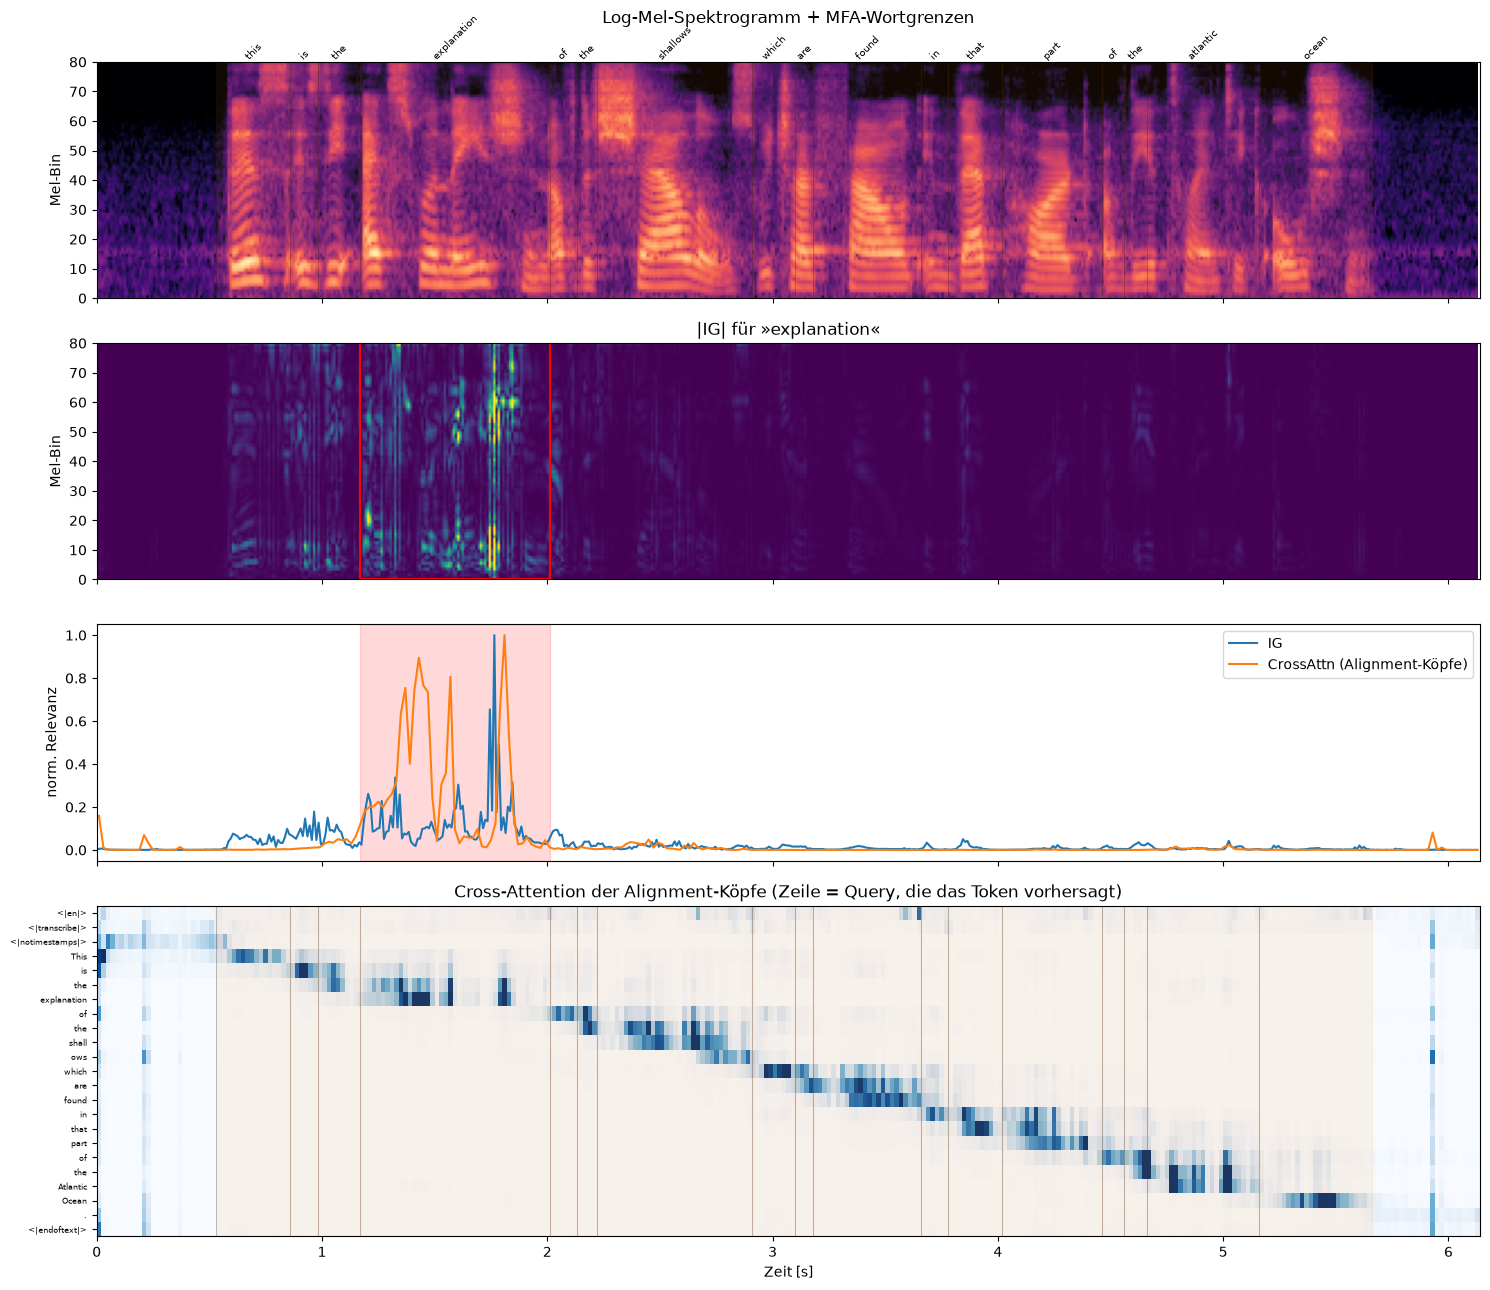

In [12]:
ex = RES[MAIN]["example"]; P = ex["prep"]; T, n_a = P["T"], P["n_a"]
wi = int(np.argmax([(w["end"] - w["start"]) * (not w["func"]) for w in P["words"]])); W = P["words"][wi]
print("Hypothese:", P["text"]); print("Fokuswort:", W["word"], f"[{W['start']:.2f}, {W['end']:.2f}] s")

def mark_words(ax, words, ymax=None, label=True):
    for w in words:
        ax.axvspan(w["start"], w["end"], color="tab:orange", alpha=0.08)
        ax.axvline(w["start"], color="k", lw=0.4, alpha=0.4)
        if label and ymax is not None:
            ax.text((w["start"] + w["end"]) / 2, ymax, w["word"], ha="center", va="bottom", fontsize=7, rotation=45)

fig, ax = plt.subplots(4, 1, figsize=(15, 13), sharex=True, gridspec_kw=dict(height_ratios=[1, 1, 1, 1.4]))
ax[0].imshow(P["feats"][0, :, :T].cpu(), origin="lower", aspect="auto", extent=[0, T * HOP, 0, N_MEL], cmap="magma")
mark_words(ax[0], P["ref_words"], N_MEL); ax[0].set_ylabel("Mel-Bin"); ax[0].set_title("Log-Mel-Spektrogramm + MFA-Wortgrenzen", pad=28)
m = np.abs(ex["ig"][wi][:, :T]); ax[1].imshow(m, origin="lower", aspect="auto", extent=[0, T * HOP, 0, N_MEL], cmap="viridis", vmax=np.quantile(m, 0.999))
ax[1].axvspan(W["start"], W["end"], fill=False, ec="r", lw=1.5); ax[1].set_ylabel("Mel-Bin"); ax[1].set_title(f"|IG| für »{W['word']}«")
t = (np.arange(T) + 0.5) * HOP
ig_prof = np.abs(ex["ig"][wi]).sum(0)[:T]; ax[2].plot(t, ig_prof / ig_prof.max(), label="IG")
cr = ex["cross"]; rows = [p - 1 for p in W["tok_pos"]]; te = (np.arange(n_a) + 0.5) * ENC_HOP
heads = RES[MAIN]["align"] or [(l, h) for l in range(cr.shape[0]) for h in range(cr.shape[1])]
ca = np.mean([cr[l, h][rows].mean(0) for l, h in heads], 0); ax[2].plot(te, ca / ca.max(), label="CrossAttn (Alignment-Köpfe)")
ax[2].axvspan(W["start"], W["end"], color="r", alpha=0.15); ax[2].legend(); ax[2].set_ylabel("norm. Relevanz")
A = np.mean([cr[l, h] for l, h in heads], 0)
ax[3].imshow(A, aspect="auto", origin="upper", extent=[0, n_a * ENC_HOP, A.shape[0], 0], cmap="Blues", vmax=np.quantile(A, 0.995))
ax[3].set_yticks(np.arange(A.shape[0]) + 0.5); ax[3].set_yticklabels(ex["tokens"][:A.shape[0]], fontsize=6)
mark_words(ax[3], P["ref_words"], label=False); ax[3].set_xlabel("Zeit [s]"); ax[3].set_title("Cross-Attention der Alignment-Köpfe (Zeile = Query, die das Token vorhersagt)")
plt.tight_layout(); plt.savefig("results/example.png", dpi=130); plt.show()

## 8 TF1 – Zeitliche Lokalisierung

**H1:** Gradientenbasierte Attribution konzentriert sich deutlich über Zufallsniveau auf das Wortsegment, mit Kontext von wenigen 100 ms.

Getestet wird einseitig per Wilcoxon-Vorzeichen-Rang-Test (`mass_in` > `chance`). Vor- und Nachkontext werden gepaart verglichen. Ein Überhang in den *Nachkontext* wäre ein Hinweis auf Koartikulation bzw. darauf, dass der bidirektionale Encoder spätere Frames einbezieht.

In [13]:
W_ALL = pd.concat([RES[m]["words"] for m in MODELS])
summary = (W_ALL.groupby(["model", "method"])
           .agg(n=("mass_in", "size"), mass_in=("mass_in", "mean"), chance=("chance", "mean"),
                lift_median=("lift", "median"), pointing=("hit", "mean"), pointing_chance=("hit_chance", "mean"),
                before=("before", "mean"), after=("after", "mean"),
                peak_off_ms=("peak_off", lambda s: 1000 * s.median()))
           .round(3))
display(summary)

print("\nWilcoxon (mass_in > chance) und Vor- vs. Nachkontext:")
for (m, meth), d in W_ALL.groupby(["model", "method"]):
    p1 = stats.wilcoxon(d.mass_in - d.chance, alternative="greater").pvalue
    p2 = stats.wilcoxon(d.after, d.before).pvalue
    print(f"  {m.split('/')[-1]:13s} {meth:28s} p(mass_in>chance)={p1:.1e}  after-before={(d.after - d.before).mean():+.3f} (p={p2:.1e})")

n  mass_in  chance  \
model               method                                               
openai/whisper-base CrossAttn (Alignment-Köpfe)  1774    0.563   0.043   
                    CrossAttn (alle Köpfe)       1774    0.187   0.043   
                    Grad×Δ                       1774    0.178   0.043   
                    IG                           1774    0.208   0.043   
                    Occlusion                    1774    0.566   0.043   
openai/whisper-tiny CrossAttn (Alignment-Köpfe)  1751    0.472   0.043   
                    CrossAttn (alle Köpfe)       1751    0.249   0.043   
                    Grad×Δ                       1751    0.212   0.043   
                    IG                           1751    0.232   0.043   
                    Occlusion                    1751    0.641   0.043   

                                                 lift_median  pointing  \
model               method                                               
openai/whisper-base CrossAttn (Alignment-Köpfe)       16.952     0.852   
                    CrossAttn (alle Köpfe)             5.394     0.050   
                    Grad×Δ                             4.371     0.633   
                    IG                                 5.433     0.736   
                    Occlusion                         15.655     0.864   
openai/whisper-tiny CrossAttn (Alignment-Köpfe)       12.451     0.678   
                    CrossAttn (alle Köpfe)             7.281     0.031   
                    Grad×Δ                             5.331     0.740   
                    IG                                 6.309     0.751   
                    Occlusion                         18.604     0.915   

                                                 pointing_chance  before  \
model               method                                                 
openai/whisper-base CrossAttn (Alignment-Köpfe)            0.049   0.134   
                    CrossAttn (alle Köpfe)                 0.049   0.123   
                    Grad×Δ                                 0.049   0.087   
                    IG                                     0.049   0.100   
                    Occlusion                              0.049   0.111   
openai/whisper-tiny CrossAttn (Alignment-Köpfe)            0.049   0.050   
                    CrossAttn (alle Köpfe)                 0.049   0.147   
                    Grad×Δ                                 0.049   0.091   
                    IG                                     0.049   0.105   
                    Occlusion                              0.049   0.095   

                                                 after  peak_off_ms  
model               method                                           
openai/whisper-base CrossAttn (Alignment-Köpfe)  0.105        -20.0  
                    CrossAttn (alle Köpfe)       0.092       -907.5  
                    Grad×Δ                       0.091         -5.0  
                    IG                           0.097        -20.0  
                    Occlusion                    0.096        -25.0  
openai/whisper-tiny CrossAttn (Alignment-Köpfe)  0.272         60.0  
                    CrossAttn (alle Köpfe)       0.109      -1115.0  
                    Grad×Δ                       0.107          5.0  
                    IG                           0.102        -15.0  
                    Occlusion                    0.092        -20.0


Wilcoxon (mass_in > chance) und Vor- vs. Nachkontext:
  whisper-base  CrossAttn (Alignment-Köpfe)  p(mass_in>chance)=1.1e-291  after-before=-0.029 (p=4.5e-40)
  whisper-base  CrossAttn (alle Köpfe)       p(mass_in>chance)=1.1e-291  after-before=-0.031 (p=2.3e-119)
  whisper-base  Grad×Δ                       p(mass_in>chance)=2.1e-291  after-before=+0.003 (p=1.5e-01)
  whisper-base  IG                           p(mass_in>chance)=3.4e-291  after-before=-0.003 (p=1.0e-03)
  whisper-base  Occlusion                    p(mass_in>chance)=1.3e-290  after-before=-0.015 (p=1.8e-06)
  whisper-tiny  CrossAttn (Alignment-Köpfe)  p(mass_in>chance)=6.2e-288  after-before=+0.222 (p=9.5e-256)
  whisper-tiny  CrossAttn (alle Köpfe)       p(mass_in>chance)=6.2e-288  after-before=-0.037 (p=5.6e-99)
  whisper-tiny  Grad×Δ                       p(mass_in>chance)=7.2e-288  after-before=+0.016 (p=4.4e-14)
  whisper-tiny  IG                           p(mass_in>chance)=9.5e-288  after-before=-0.003 (p=1.7e-03

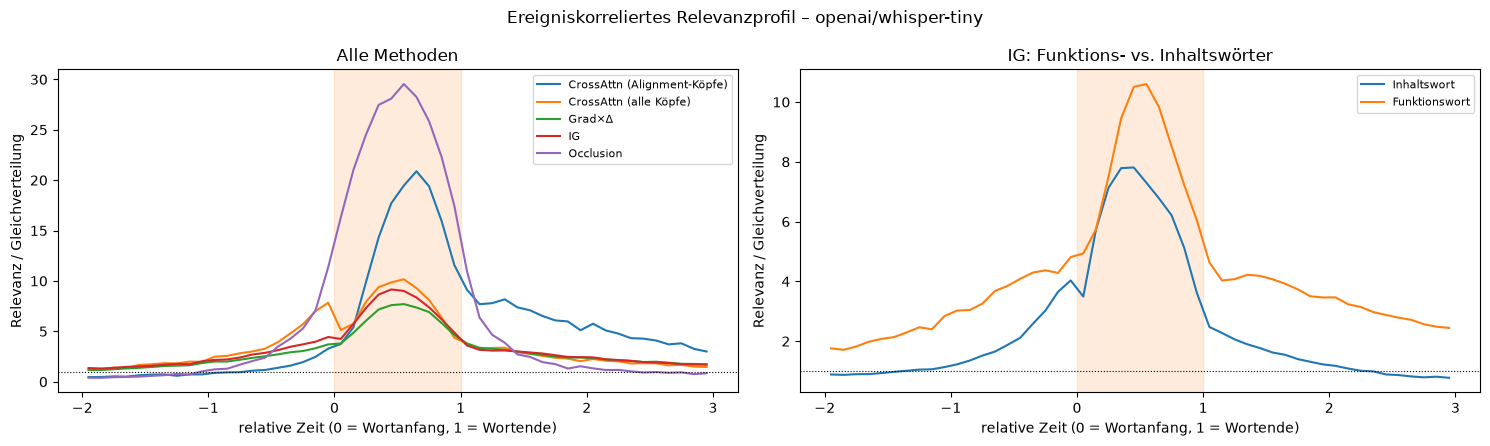

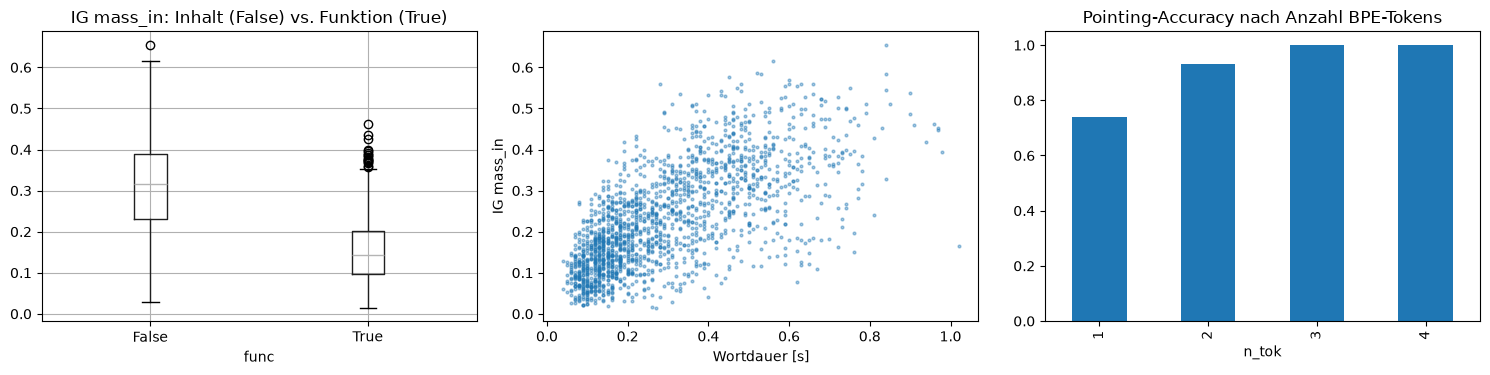

Lift Funktions- vs. Inhaltswort: Median 7.13 vs 5.62, Mann-Whitney p=3.6e-18
Spearman(Wortdauer, mass_in) = 0.70 (p=6.6e-260) – Achtung: chance wächst mit der Dauer, daher auch lift betrachten


In [14]:
centers = (BINS[:-1] + BINS[1:]) / 2
E = RES[MAIN]["erp"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for meth, d in E.groupby("method"):
    ax[0].plot(centers, np.nanmean(np.stack(d.prof), 0), label=meth)
for f, d in E[E.method == "IG"].groupby("func"):
    ax[1].plot(centers, np.nanmean(np.stack(d.prof), 0), label="Funktionswort" if f else "Inhaltswort")
for a, ttl in zip(ax, ["Alle Methoden", "IG: Funktions- vs. Inhaltswörter"]):
    a.axvspan(0, 1, color="tab:orange", alpha=0.15); a.axhline(1, color="k", ls=":", lw=0.8)
    a.set_xlabel("relative Zeit (0 = Wortanfang, 1 = Wortende)"); a.set_ylabel("Relevanz / Gleichverteilung"); a.set_title(ttl); a.legend(fontsize=8)
plt.suptitle(f"Ereigniskorreliertes Relevanzprofil – {MAIN}"); plt.tight_layout(); plt.savefig("results/erp.png", dpi=130); plt.show()

d = W_ALL[(W_ALL.model == MAIN) & (W_ALL.method == "IG")]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
d.boxplot("mass_in", by="func", ax=ax[0]); ax[0].set_title("IG mass_in: Inhalt (False) vs. Funktion (True)")
ax[1].scatter(d.w_dur, d.mass_in, s=4, alpha=0.4); ax[1].set_xlabel("Wortdauer [s]"); ax[1].set_ylabel("IG mass_in")
d.groupby("n_tok").hit.mean().plot.bar(ax=ax[2]); ax[2].set_title("Pointing-Accuracy nach Anzahl BPE-Tokens")
plt.suptitle(""); plt.tight_layout(); plt.savefig("results/tf1_wordtypes.png", dpi=130); plt.show()
mw = stats.mannwhitneyu(d[d.func].lift, d[~d.func].lift)
rho = stats.spearmanr(d.w_dur, d.mass_in)
print(f"Lift Funktions- vs. Inhaltswort: Median {d[d.func].lift.median():.2f} vs {d[~d.func].lift.median():.2f}, Mann-Whitney p={mw.pvalue:.1e}")
print(f"Spearman(Wortdauer, mass_in) = {rho.statistic:.2f} (p={rho.pvalue:.1e}) – Achtung: chance wächst mit der Dauer, daher auch lift betrachten")

## 9 TF2 – Spektrale Merkmale

Für jedes Wort wird die |IG|-Masse im Wortsegment pro Mel-Bin normiert und mit dem Energieprofil $x-x_0$ im selben Segment verglichen. Ein Verhältnis > 1 heißt: Das Band ist *relevanter, als seine Energie erwarten lässt*. Damit lässt sich prüfen, ob IG nur Energie nachzeichnet. Die Band-Occlusion liefert eine kausale Gegenprobe.

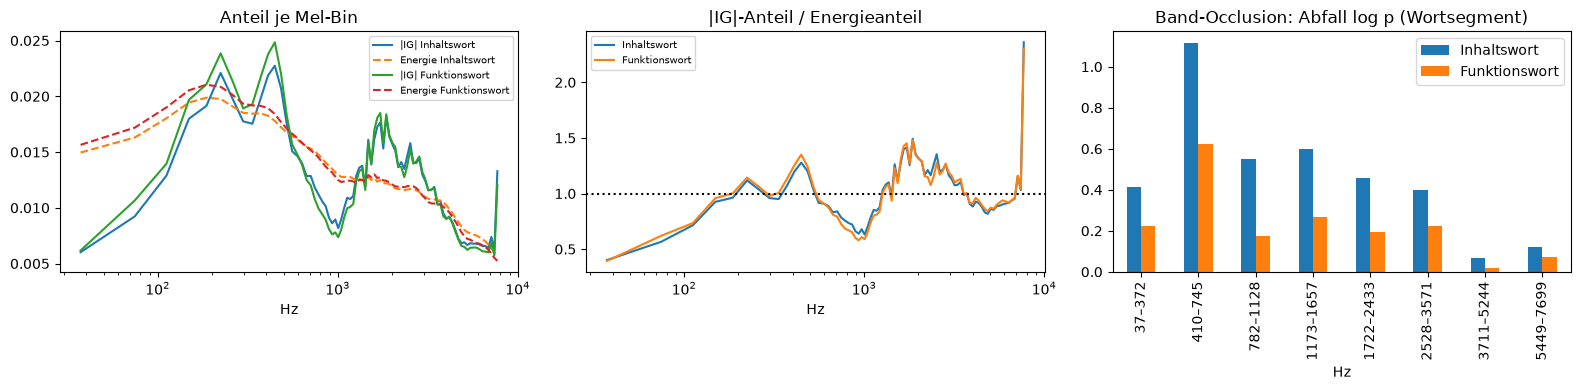

Median Spearman(|IG|-Profil, Energieprofil) je Wort: 0.67
Wichtigstes Band (Occlusion): 410–745 Hz


In [15]:
freqs = librosa.mel_frequencies(n_mels=N_MEL + 2, fmin=0, fmax=SR / 2)[1:-1]   # Mittenfrequenzen der Slaney-Mel-Filter
S = RES[MAIN]["spec"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for f, d in S.groupby("func"):
    lab = "Funktionswort" if f else "Inhaltswort"
    ig_m, en_m = np.stack(d.ig).mean(0), np.stack(d.energy).mean(0)
    ax[0].plot(freqs, ig_m, label=f"|IG| {lab}"); ax[0].plot(freqs, en_m, "--", label=f"Energie {lab}")
    ax[1].plot(freqs, ig_m / en_m, label=lab)
ax[0].set_title("Anteil je Mel-Bin"); ax[1].set_title("|IG|-Anteil / Energieanteil"); ax[1].axhline(1, color="k", ls=":")
B = RES[MAIN]["bands"]; e = RES[MAIN]["band_edges"]
bl = [f"{freqs[e[k]]:.0f}–{freqs[e[k + 1] - 1]:.0f}" for k in range(len(e) - 1)]
bm = B.groupby("func")[[f"b{k}" for k in range(len(e) - 1)]].mean().T; bm.index = bl
bm.columns = ["Inhaltswort" if not c else "Funktionswort" for c in bm.columns]
bm.plot.bar(ax=ax[2]); ax[2].set_title("Band-Occlusion: Abfall log p (Wortsegment)"); ax[2].set_xlabel("Hz")
for a in ax[:2]: a.set_xscale("log"); a.set_xlabel("Hz"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("results/tf2_spectral.png", dpi=130); plt.show()

ig_all = np.stack(S.ig); en_all = np.stack(S.energy)
rho = np.nanmedian([stats.spearmanr(a, b).statistic for a, b in zip(ig_all, en_all)])
print(f"Median Spearman(|IG|-Profil, Energieprofil) je Wort: {rho:.2f}")
print("Wichtigstes Band (Occlusion):", bm.mean(1).idxmax(), "Hz")

## 10 TF3 – Cross-Attention-Köpfe des Decoders

**H2:** Nur wenige Köpfe in mittleren und späten Decoder-Schichten richten ihre Cross-Attention eng an den Wortgrenzen aus. Diese sollten mit OpenAIs `alignment_heads` übereinstimmen.

Die Heatmap zeigt die Pointing-Accuracy pro (Schicht, Kopf). Die Alignment-Köpfe sind mit ★ markiert. Rechts steht der Anteil der Attention auf dem Padding.

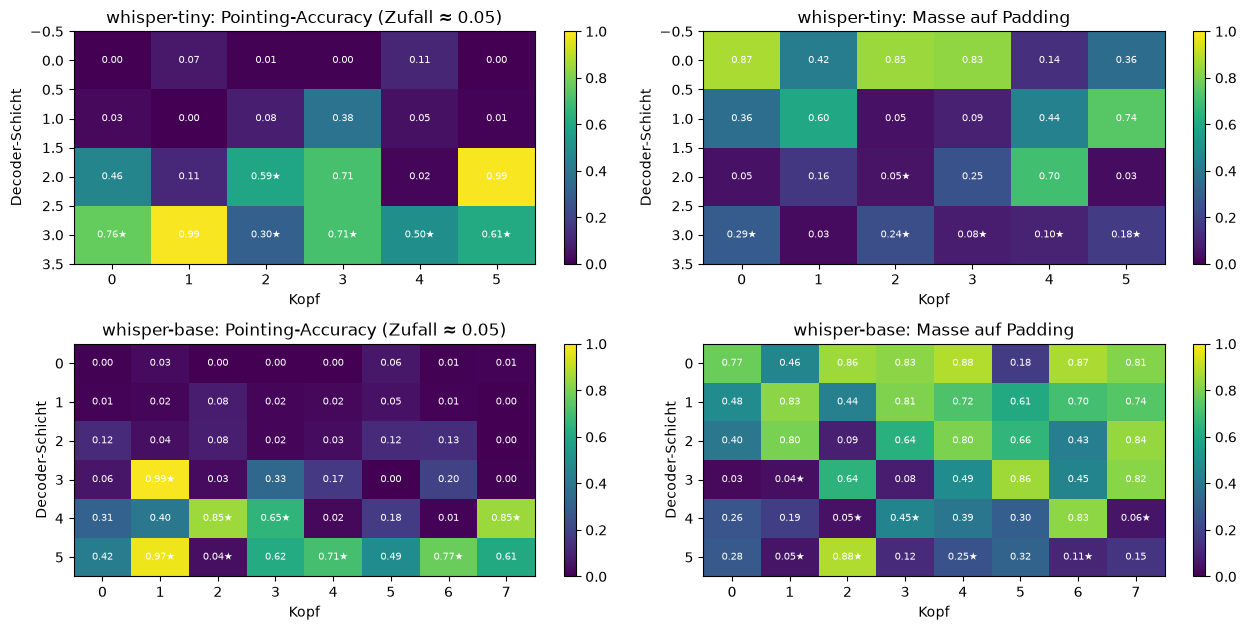

openai/whisper-tiny: Top-6 Köpfe [(np.int64(3), np.int64(1)), (np.int64(2), np.int64(5)), (np.int64(3), np.int64(0)), (np.int64(3), np.int64(3)), (np.int64(2), np.int64(3)), (np.int64(3), np.int64(5))] | Überlappung mit alignment heads: 3/6 | Köpfe mit Pointing > 0.5: 7/24 | Mittel je Schicht: [0.03 0.09 0.48 0.65]
openai/whisper-base: Top-6 Köpfe [(np.int64(3), np.int64(1)), (np.int64(5), np.int64(1)), (np.int64(4), np.int64(2)), (np.int64(4), np.int64(7)), (np.int64(5), np.int64(6)), (np.int64(5), np.int64(4))] | Überlappung mit alignment heads: 6/8 | Köpfe mit Pointing > 0.5: 9/48 | Mittel je Schicht: [0.02 0.03 0.07 0.22 0.41 0.58]


In [16]:
fig, axes = plt.subplots(len(MODELS), 2, figsize=(13, 3.2 * len(MODELS)), squeeze=False)
for i, m in enumerate(MODELS):
    r = RES[m]; chance = W_ALL[(W_ALL.model == m) & (W_ALL.method == "IG")].hit_chance.mean()
    for j, (k, ttl) in enumerate([("hit", f"Pointing-Accuracy (Zufall ≈ {chance:.2f})"), ("pad", "Masse auf Padding")]):
        a = axes[i, j]; M = r["cross"][k]
        im = a.imshow(M, cmap="viridis", vmin=0, vmax=1, aspect="auto"); plt.colorbar(im, ax=a)
        for (l, h), v in np.ndenumerate(M):
            a.text(h, l, f"{v:.2f}" + ("★" if r["align"] and (l, h) in r["align"] else ""), ha="center", va="center", fontsize=7, color="w")
        a.set_xlabel("Kopf"); a.set_ylabel("Decoder-Schicht"); a.set_title(f"{m.split('/')[-1]}: {ttl}")
plt.tight_layout(); plt.savefig("results/tf3_cross_heads.png", dpi=130); plt.show()

for m in MODELS:
    r = RES[m]; M = r["cross"]["hit"]; top = np.dstack(np.unravel_index(np.argsort(-M, axis=None), M.shape))[0][:6]
    al = r["align"] or []
    print(f"{m}: Top-6 Köpfe {[tuple(x) for x in top]} | Überlappung mit alignment heads: "
          f"{len(set(map(tuple, top[:len(al)])) & set(al))}/{len(al)} | "
          f"Köpfe mit Pointing > 0.5: {(M > 0.5).sum()}/{M.size} | Mittel je Schicht: {M.mean(1).round(2)}")

## 11 TF4 – Self-Attention-Köpfe des Encoders

**H3:** In frühen Encoder-Schichten dominieren lokale, diagonale Muster, in späteren Schichten globalere Muster.

Heuristische Typisierung pro Kopf (Schwellen bewusst einfach gehalten und dokumentiert):
* *Sink*: `pad_mass` > 0.5
* *Vorgänger/Nachfolger*: `prev` oder `next` > 0.3
* *lokal*: `local` > 0.5
* sonst *global*

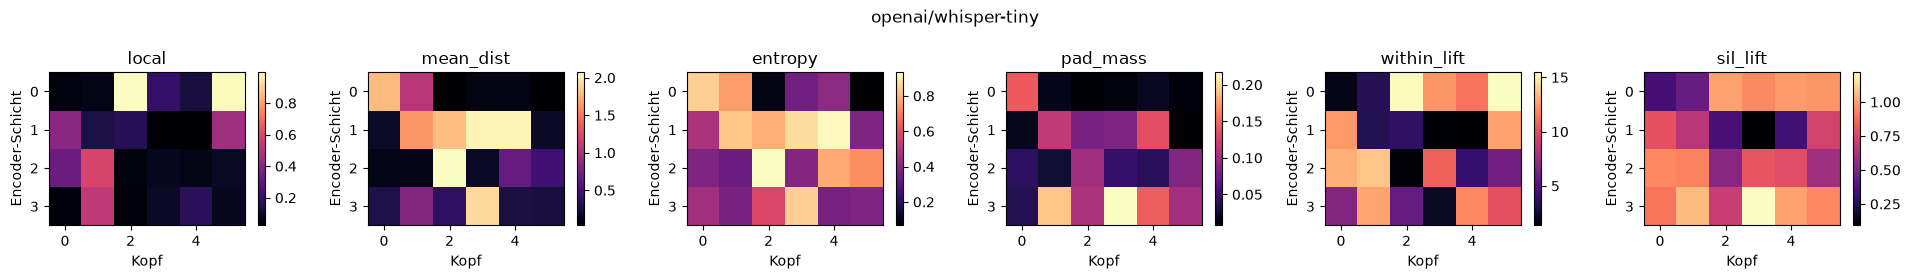

,0,1,2,3,4,5
Schicht,,,,,,
0,global,global,Nachfolger,global,global,Vorgänger
1,global,global,global,global,global,global
2,global,lokal,global,global,global,global
3,global,lokal,global,global,global,global


openai/whisper-tiny: Spearman(Schicht, mean_dist)=0.22 (p=0.3), Spearman(Schicht, local)=-0.20 (p=0.34)


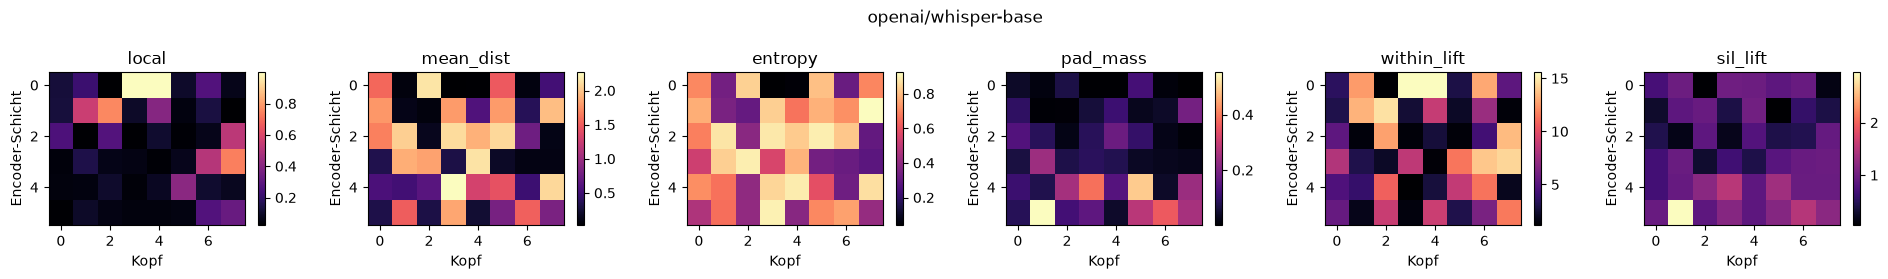

,0,1,2,3,4,5,6,7
Schicht,,,,,,,,
0,global,global,global,Nachfolger,Vorgänger,global,global,global
1,global,lokal,Nachfolger,global,global,global,global,global
2,global,global,global,global,global,global,global,lokal
3,global,global,global,global,global,global,lokal,lokal
4,global,global,global,global,global,global,global,global
5,global,Sink,global,global,global,global,global,global


openai/whisper-base: Spearman(Schicht, mean_dist)=0.12 (p=0.41), Spearman(Schicht, local)=-0.26 (p=0.077)


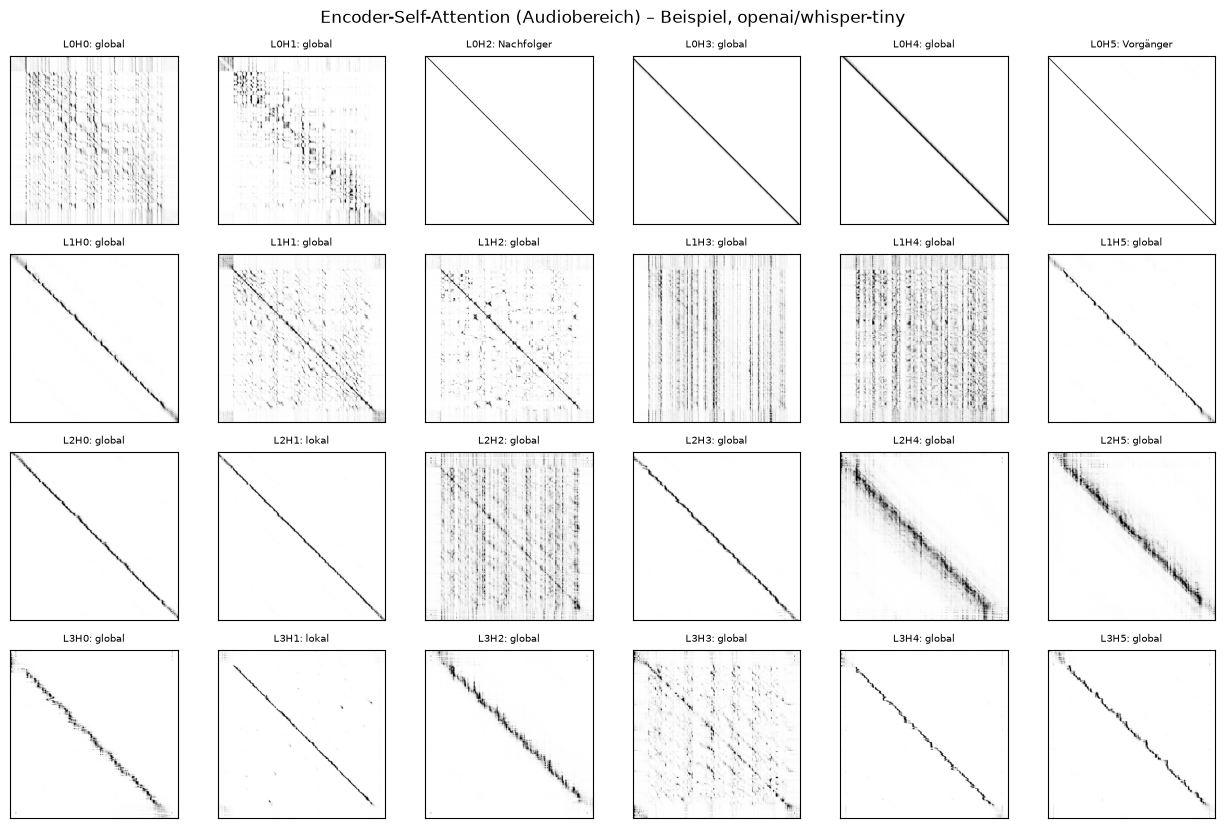

In [17]:
def head_type(s, l, h):
    if s["pad_mass"][l, h] > 0.5: return "Sink"
    if s["prev"][l, h] > 0.3: return "Vorgänger"
    if s["next"][l, h] > 0.3: return "Nachfolger"
    if s["local"][l, h] > 0.5: return "lokal"
    return "global"

keys = ["local", "mean_dist", "entropy", "pad_mass", "within_lift", "sil_lift"]
for m in MODELS:
    s = RES[m]["enc"]
    fig, ax = plt.subplots(1, len(keys), figsize=(3.2 * len(keys), 2.8))
    for a, k in zip(ax, keys):
        im = a.imshow(s[k], aspect="auto", cmap="magma"); plt.colorbar(im, ax=a); a.set_title(k)
        a.set_xlabel("Kopf"); a.set_ylabel("Encoder-Schicht")
    plt.suptitle(m); plt.tight_layout(); plt.savefig(f"results/tf4_enc_{m.split('/')[-1]}.png", dpi=130); plt.show()
    types = pd.DataFrame([[head_type(s, l, h) for h in range(s["local"].shape[1])] for l in range(s["local"].shape[0])])
    types.index.name = "Schicht"; display(types)
    L = np.repeat(np.arange(s["local"].shape[0]), s["local"].shape[1])
    r1, r2 = stats.spearmanr(L, s["mean_dist"].ravel()), stats.spearmanr(L, s["local"].ravel())
    print(f"{m}: Spearman(Schicht, mean_dist)={r1.statistic:.2f} (p={r1.pvalue:.2g}), "
          f"Spearman(Schicht, local)={r2.statistic:.2f} (p={r2.pvalue:.2g})")

ex = RES[MAIN]["example"]; Le, He = ex["enc"].shape[:2]
fig, ax = plt.subplots(Le, He, figsize=(2.1 * He, 2.1 * Le))
for l in range(Le):
    for h in range(He):
        a = ax[l, h]; M = ex["enc"][l, h].astype(np.float32)
        a.imshow(M, cmap="Greys", vmax=np.quantile(M, 0.995)); a.set_xticks([]); a.set_yticks([])
        a.set_title(f"L{l}H{h}: {head_type(RES[MAIN]['enc'], l, h)}", fontsize=7)
plt.suptitle(f"Encoder-Self-Attention (Audiobereich) – Beispiel, {MAIN}"); plt.tight_layout()
plt.savefig("results/tf4_enc_maps.png", dpi=110); plt.show()

## 12 TF5 – Faithfulness: Deletion und Ablation

**H4:** Attention-Gewichte sind schwächer kausal mit der Ausgabe verknüpft als Attribution. Konkret: (a) Die Deletion-Kurven von IG und Occlusion fallen steiler als die von Cross-Attention. (b) Die Lokalisierungsgüte eines Kopfes sagt seine Ablationswirkung nur schwach voraus.

**Vorsicht beim Deuten** (Hooker et al., 2019): Das Entfernen von Frames erzeugt Eingaben, die das Modell im Training nie gesehen hat. Die Silence-Baseline mildert das, beseitigt es aber nicht.

frac                                             0.25  0.50  1.00  2.00  4.00
model               method                                                   
openai/whisper-base CrossAttn (Alignment-Köpfe) -0.16 -0.76 -2.78 -5.52 -6.01
                    CrossAttn (alle Köpfe)      -0.06 -0.22 -1.38 -4.10 -5.66
                    Grad×Δ                      -0.17 -0.66 -2.15 -4.17 -5.42
                    IG                          -0.25 -0.92 -2.77 -4.52 -5.58
                    Occlusion                   -0.59 -1.30 -3.12 -4.60 -5.03
                    Oracle                      -0.14 -1.10 -5.04 -6.60 -6.21
                    Zufall                      -0.01 -0.02 -0.04 -0.13 -0.81
openai/whisper-tiny CrossAttn (Alignment-Köpfe) -0.30 -1.19 -3.86 -5.70 -6.07
                    CrossAttn (alle Köpfe)      -0.13 -0.52 -3.01 -5.98 -6.45
                    Grad×Δ                      -0.44 -1.25 -3.57 -5.65 -6.32
                    IG                          -0.56 -1.62 -4.05 -5.71 -6.30
                    Occlusion                   -0.90 -2.10 -4.48 -5.67 -6.02
                    Oracle                      -0.32 -1.61 -6.02 -7.04 -6.53
                    Zufall                      -0.01 -0.05 -0.12 -0.37 -1.39

AUC (mittl. Δ log p)
model               method                                           
openai/whisper-tiny Oracle                                      -4.30
                    Occlusion                                   -3.83
openai/whisper-base Oracle                                      -3.82
openai/whisper-tiny IG                                          -3.65
                    Grad×Δ                                      -3.45
                    CrossAttn (Alignment-Köpfe)                 -3.42
                    CrossAttn (alle Köpfe)                      -3.22
openai/whisper-base CrossAttn (Alignment-Köpfe)                 -3.05
                    Occlusion                                   -2.93
                    IG                                          -2.81
                    Grad×Δ                                      -2.51
                    CrossAttn (alle Köpfe)                      -2.28
openai/whisper-tiny Zufall                                      -0.39
openai/whisper-base Zufall                                      -0.20

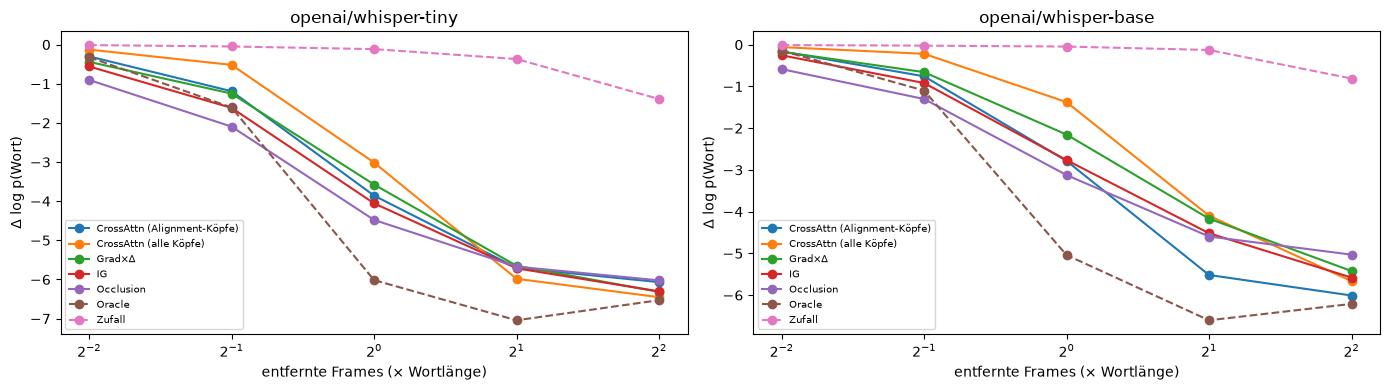

In [18]:
D = pd.concat([RES[m]["deletion"] for m in MODELS])
curves = D.groupby(["model", "method", "frac"]).delta.mean().unstack("frac")
auc = D.groupby(["model", "method"]).delta.mean().rename("AUC (mittl. Δ log p)").sort_values()
display(curves.round(2)); display(auc.round(2).to_frame())
fig, ax = plt.subplots(1, len(MODELS), figsize=(7 * len(MODELS), 4), squeeze=False)
for a, m in zip(ax[0], MODELS):
    for meth, row in curves.loc[m].iterrows():
        a.plot(row.index, row.values, marker="o", label=meth, ls="--" if meth in ("Oracle", "Zufall") else "-")
    a.set_xscale("log", base=2); a.set_xlabel("entfernte Frames (× Wortlänge)"); a.set_ylabel("Δ log p(Wort)"); a.set_title(m); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("results/tf5_deletion.png", dpi=130); plt.show()

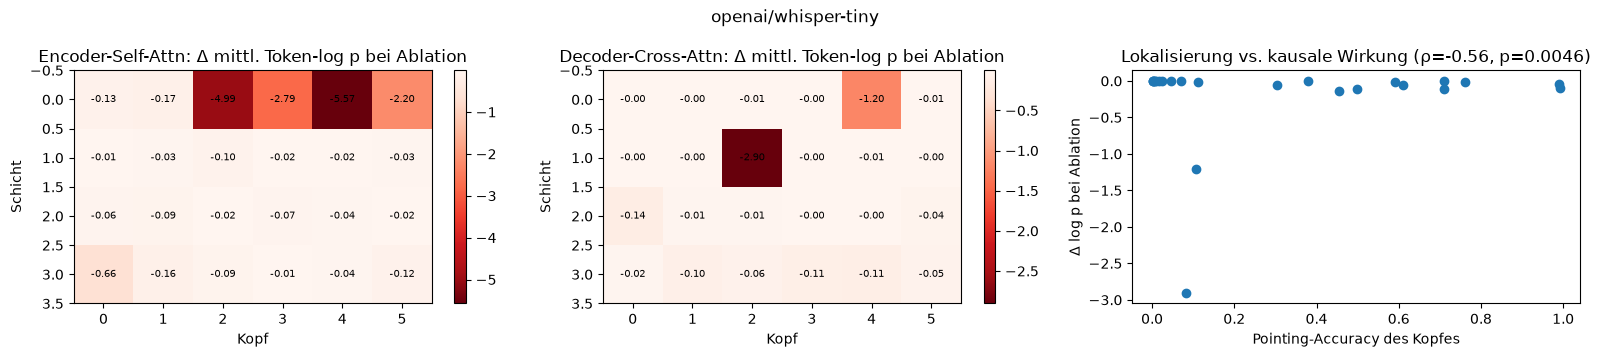

openai/whisper-tiny – Gruppenablation (Alignment-Köpfe vs. gleich große Zufallsmengen):


,label,d_logprob,wer,d_wer
48,alignment heads,-1.556,1.459,1.383
49,Zufall 0,-1.031,2.103,2.028
50,Zufall 1,-0.132,0.157,0.081
51,Zufall 2,-0.132,0.146,0.070
52,Zufall 3,-0.478,0.217,0.141
53,Zufall 4,-0.382,0.444,0.368


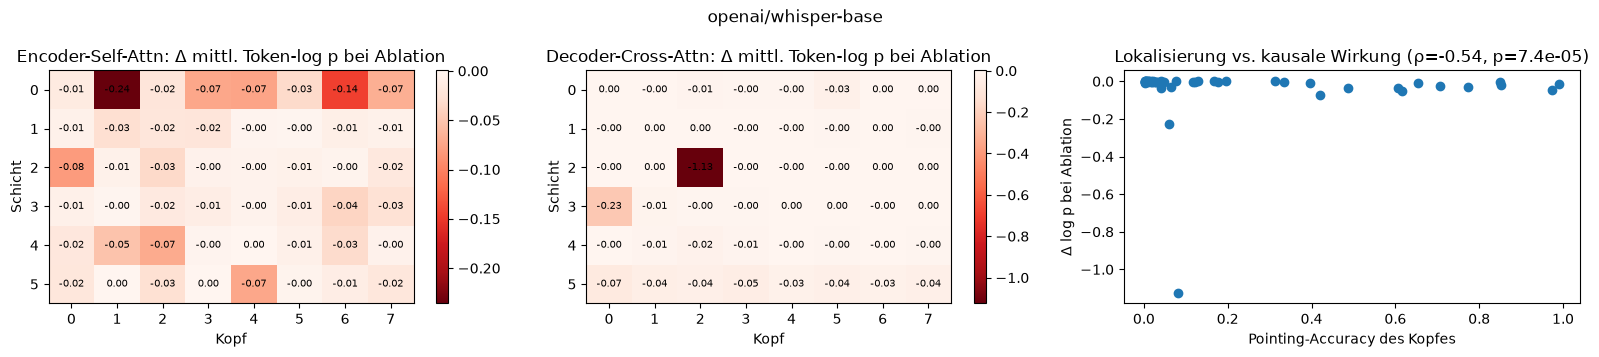

openai/whisper-base – Gruppenablation (Alignment-Köpfe vs. gleich große Zufallsmengen):


,label,d_logprob,wer,d_wer
96,alignment heads,-1.562,0.932,0.868
97,Zufall 0,-0.094,0.078,0.013
98,Zufall 1,-1.613,4.734,4.669
99,Zufall 2,-2.657,5.326,5.261
100,Zufall 3,-0.160,0.254,0.190
101,Zufall 4,-1.189,3.784,3.719


In [19]:
for m in MODELS:
    r = RES[m]; A = r["ablation"]
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    for a, kind, L, H, ttl in [(ax[0], "enc_self", r["L_enc"], r["H_enc"], "Encoder-Self-Attn"),
                               (ax[1], "dec_cross", r["L_dec"], r["H_dec"], "Decoder-Cross-Attn")]:
        d = A[(A.kind == kind) & A.label.str.match(r"^[EC]\d")]
        M = np.zeros((L, H))
        for _, row in d.iterrows(): (l, h), = row.heads; M[l, h] = row.d_logprob
        im = a.imshow(M, cmap="Reds_r", aspect="auto"); plt.colorbar(im, ax=a)
        for (l, h), v in np.ndenumerate(M): a.text(h, l, f"{v:.2f}", ha="center", va="center", fontsize=7)
        a.set_title(f"{ttl}: Δ mittl. Token-log p bei Ablation"); a.set_xlabel("Kopf"); a.set_ylabel("Schicht")
    d = A[(A.kind == "dec_cross") & A.label.str.match(r"^C\d")]
    loc = np.array([r["cross"]["hit"][row.heads[0]] for _, row in d.iterrows()])
    ax[2].scatter(loc, d.d_logprob); ax[2].set_xlabel("Pointing-Accuracy des Kopfes"); ax[2].set_ylabel("Δ log p bei Ablation")
    rho = stats.spearmanr(loc, d.d_logprob)
    ax[2].set_title(f"Lokalisierung vs. kausale Wirkung (ρ={rho.statistic:.2f}, p={rho.pvalue:.2g})")
    plt.suptitle(m); plt.tight_layout(); plt.savefig(f"results/tf5_ablation_{m.split('/')[-1]}.png", dpi=130); plt.show()
    g = A[~A.label.str.match(r"^[EC]\d")][["label", "d_logprob", "wer", "d_wer"]]
    print(m, "– Gruppenablation (Alignment-Köpfe vs. gleich große Zufallsmengen):"); display(g.round(3))

## 13 Modellvergleich tiny vs. base

In [20]:
rows = []
for m in MODELS:
    r = RES[m]; w = r["words"]; A = r["ablation"]
    ig = w[w.method == "IG"]
    row = dict(model=m, WER=r["utt"].wer.mean(), IG_mass_in=ig.mass_in.mean(), IG_lift=ig.lift.median(),
               IG_pointing=ig.hit.mean(), pointing_chance=ig.hit_chance.mean(),
               best_cross_head=r["cross"]["hit"].max(), mean_cross_head=r["cross"]["hit"].mean(),
               enc_local_first=r["enc"]["local"][0].mean(), enc_local_last=r["enc"]["local"][-1].mean(),
               enc_pad_mass=r["enc"]["pad_mass"].mean(),
               del_auc_IG=r["deletion"].query("method=='IG'").delta.mean(),
               del_auc_Oracle=r["deletion"].query("method=='Oracle'").delta.mean())
    if r["align"]:
        row["align_heads_pointing"] = np.mean([r["cross"]["hit"][l, h] for l, h in r["align"]])
        g = A[A.label == "alignment heads"].d_wer.values[0]; z = A[A.label.str.startswith("Zufall")].d_wer.mean()
        row.update(dWER_align_heads=g, dWER_random_heads=z)
    rows.append(row)
CMP = pd.DataFrame(rows).set_index("model").T.round(3); display(CMP)
CMP.to_csv("results/model_comparison.csv")
json.dump(dict(summary=summary.reset_index().to_dict("records"), comparison=CMP.to_dict(), cfg=CFG),
          open("results/summary.json", "w"), indent=1, default=str)

model,openai/whisper-tiny,openai/whisper-base
WER,0.084,0.066
IG_mass_in,0.232,0.208
IG_lift,6.309,5.433
IG_pointing,0.751,0.736
pointing_chance,0.049,0.049
best_cross_head,0.991,0.991
mean_cross_head,0.312,0.220
enc_local_first,0.408,0.350
enc_local_last,0.162,0.115
enc_pad_mass,0.075,0.120


## 14 Reflexion – Leitfragen zur Interpretation

Nach dem Lauf zu beantworten und in `README.md` / Präsentation zu übernehmen:

1. **H1:** Liegt IG-`lift` deutlich über 1? Wie groß ist der Nachkontext (`after`) im Vergleich zum Vorkontext? Zeigt das ERP-Profil Spitzen am Wortanfang/-ende (Übergänge) oder in der Mitte (Vokalkern)?
2. **Funktionswörter:** Sind sie schlechter lokalisiert? Erwartbar, denn sie sind kurz, reduziert und stärker vom Sprachmodell-Kontext des Decoders bestimmt als von der Akustik.
3. **H2:** Decken sich die besten Pointing-Köpfe mit den `alignment_heads`? Wie viel Masse geht aufs Padding? Hohe Padding-Masse spricht für einen *Attention Sink* und nicht für Lokalisierung.
4. **H3:** Wächst `mean_dist` über die Schichten? Gibt es `within_lift` > 1, also wortgebundene Encoder-Köpfe?
5. **H4:** Liegen die Deletion-Kurven der Attention-Profile näher an `Zufall` oder an `Oracle`? Korreliert Pointing-Accuracy mit der Ablationswirkung?
6. **Mögliche Fehlerquellen:** Out-of-Distribution-Effekt beim Entfernen von Frames, Abhängigkeit von der Baseline, MFA-Ungenauigkeit (~10–20 ms), Selektionsbias (nur korrekt erkannte Wörter), Gradientensättigung (Grad×Δ vs. IG), Wörter aus mehreren Tokens, Teacher Forcing auf die eigene Hypothese.